# Notebook 3: ปรับปรุงทีละขั้น แล้ววัดผล (คู่กับ README บทที่ 10-11)

**ทำ notebook นี้เพื่ออะไร:** แก้จุดอ่อน 6 จุดจาก Notebook 2 ทีละจุด และ **ดูผลของแต่ละการแก้ด้วยข้อมูลจริง** ก่อนจะวัดรวมท้าย notebook
นี่คือเนื้อหาของโจทย์ข้อ 2 (ปรับปรุง) และข้อ 3 (ต่างกันตรงไหน ดีขึ้นอย่างไร เพราะอะไร)

ระบบใหม่อยู่ใน `steps/step07_improved.py` แต่ละการแก้มีป้าย `[P1]`..`[P7]` ในโค้ด:

```
.md ─► [P1] ตัดตามหัวข้อ ≤800 ตัวอักษร + overlap + breadcrumb
    ─► [P2] LLM สร้าง context (เห็นสารบัญ + section แม่, ตอบไทย + คำพ้อง)
    ─► [P4] bge-m3 embed (breadcrumb + context + chunk)
    ─► OpenSearch index เดียว: kNN (HNSW) + [P3] BM25 analyzer "thai"
คำถาม ─► BM25 top-20 + kNN top-20 ─► [P5] RRF (rank เริ่ม 1) ─► top-20
      ─► [P6] cross-encoder bge-reranker-v2-m3 ─► top-5
      ─► [P7] LLM relevance filter ─► prompt ที่บังคับตอบจาก context + อ้างอิง [n]
```

**กติกาของห้อง:** ก่อนรันแต่ละหัวข้อ ให้เขียนสมมติฐาน "ถ้าแก้ ___ แล้ว ___ น่าจะ ขึ้น/ลง เพราะ ___" แล้วค่อยดูผล

## 0. เตรียมสภาพแวดล้อม และสร้าง index ของระบบใหม่

**คืออะไร:** `ingest` = อ่านเอกสาร → ตัด chunk → ให้ LLM เขียน context → embed → ใส่ OpenSearch

**ทำทำไมต้องมี `results/contexts.json`:** การสร้าง context ต้องเรียก LLM 159 ครั้ง (~60 นาทีบน free tier)
โฟลเดอร์เวิร์กช็อปแจกไฟล์ที่สร้างไว้แล้ว โค้ดจะใช้ของในไฟล์และข้ามการเรียก LLM เหลือแค่เวลา embed (~2 นาที)
อยากเห็น LLM สร้างเอง ให้ลบไฟล์นี้ก่อนรัน cell ด้านล่าง

In [1]:
import os, sys, json, re
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "steps"))

import statistics
import pandas as pd
from common import notebook_setup
notebook_setup()                      # ปิดข้อความรก + เลือก font ไทยให้กราฟ
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 90)

import step07_improved as imp       # ระบบใหม่
import step08_evaluate as ev         # ตัววัดผล + query ของระบบครู
from common import opensearch, read_corpus

client = opensearch()
QUESTIONS = {q["id"]: q for q in ev.QUESTIONS}
print("context ที่แจกไว้:", len(json.loads(imp.CONTEXT_CACHE.read_text(encoding="utf-8"))) if imp.CONTEXT_CACHE.exists() else "ไม่มี (จะเรียก LLM สร้างใหม่)")

if client.indices.exists(index=imp.INDEX) and client.count(index=imp.INDEX)["count"] > 0:
    print(f"มี index {imp.INDEX} แล้ว ({client.count(index=imp.INDEX)['count']} chunk) ข้ามการ ingest")
else:
    imp.ingest()

context ที่แจกไว้: 157


มี index workshop-improved แล้ว (159 chunk) ข้ามการ ingest


---
## [P1] Chunking: ตามหัวข้อ + จำกัดขนาด + overlap + breadcrumb  (แก้จุดอ่อน 3)

### คืออะไร
ตัวตัดใหม่ `chunk_markdown()` ทำ 4 อย่าง:
1. **ตัดตามหัวข้อ markdown ก่อน** (`#`, `##`, ...) ให้แต่ละ chunk อยู่ในเรื่องเดียว
2. section ไหน **ยาวเกิน 800 ตัวอักษร** ตัดต่อตามบรรทัด/ช่องว่าง (ภาษาไทยเว้นวรรคระหว่างประโยค ตัดตรงนั้นจึงไม่ตัดกลางคำ)
3. **overlap 1 บรรทัด** ระหว่าง chunk ที่ติดกัน กันข้อมูลตรงรอยต่อหาย
4. **breadcrumb** `ชื่อเอกสาร > หัวข้อ > หัวข้อย่อย` ติดไปกับทุก chunk

### ทำทำไม
- chunk ใหญ่ (สูงสุด 8,404 ตัวอักษร) ทำให้ embedding เบลอ, reranker อ่านไม่ครบ (รับได้ 512 token), ส่งขยะให้ LLM เยอะ
- แต่ chunk เล็กเกินก็ไม่รู้ว่าพูดเรื่องอะไร ("12-24 วัน" ของอะไร?) → แก้ด้วย breadcrumb
- ทางเลือกอื่นที่ไม่เลือก: ตัดทุก 800 ตัวอักษรตรง ๆ (ตัดกลางเรื่อง), semantic chunking (ช้า ซับซ้อน ผลไม่นิ่ง) — ละเอียดใน README 10.2

### ทำยังไง (ในโค้ด `chunk_markdown()`)
1. อ่านไฟล์ทีละบรรทัด ถ้าเป็นหัวข้อ (`#`) → ปิด section เดิมแล้วอัปเดต breadcrumb ด้วย `stack = stack[: level - 1] + [head]`
2. ถ้าเป็นเนื้อหา → สะสมไว้ พอเจอหัวข้อใหม่ค่อย "flush" ตัด section ที่สะสมเป็น chunk ไม่เกิน 800 ตัวอักษร (บรรทัดยาวเกินตัดที่ช่องว่าง)
3. ตอนปิด chunk เอาบรรทัดสุดท้ายติดไปด้วย (overlap) ถ้าบรรทัดนั้นสั้นกว่า 300 ตัวอักษร
4. เก็บ 4 อย่างต่อ chunk: ไฟล์, breadcrumb, เนื้อหา, section แม่ (ใช้ใน P2)
5. ใน notebook: ตัดทั้ง 4 ไฟล์ แล้วเทียบสถิติขนาดและ chunk ตัวอย่างกับของครู

### ทายก่อนรัน
จาก 53 chunk ของครู ระบบใหม่จะได้กี่ chunk? chunk ที่ยาวที่สุดจะยาวประมาณเท่าไร?

In [2]:
corpus = read_corpus()
new_chunks = [c for name, text in corpus.items() for c in imp.chunk_markdown(text, name)]
teacher_docs = [h["_source"] for h in client.search(index="anthropic-bm25-index", body={"size": 1000, "query": {"match_all": {}}})["hits"]["hits"]]

def stats(lens):
    return {"จำนวน chunk": len(lens), "min": min(lens), "median": int(statistics.median(lens)), "max": max(lens), "ยาวเกิน 1,500": sum(l > 1500 for l in lens)}
pd.DataFrame({"ระบบครู": stats([len(d["content"]) for d in teacher_docs]),
              "ระบบใหม่": stats([len(c["content"]) for c in new_chunks])})

,ระบบครู,ระบบใหม่
จำนวน chunk,53,159
min,112,26
median,1188,637
max,8404,1074
"ยาวเกิน 1,500",22,0


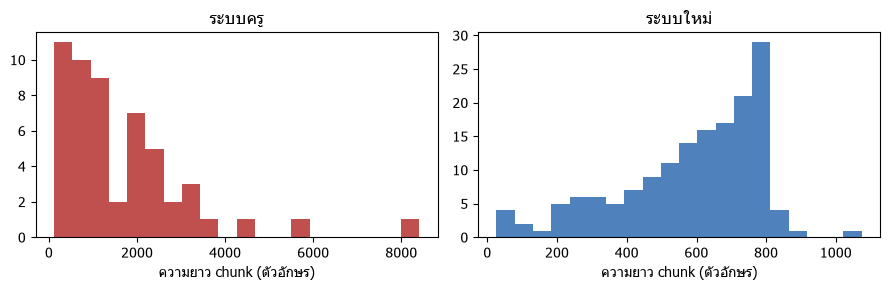

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3), sharey=False)
ax[0].hist([len(d["content"]) for d in teacher_docs], bins=20, color="#c0504d"); ax[0].set_title("ระบบครู")
ax[1].hist([len(c["content"]) for c in new_chunks], bins=20, color="#4f81bd"); ax[1].set_title("ระบบใหม่")
for a in ax: a.set_xlabel("ความยาว chunk (ตัวอักษร)")
plt.tight_layout(); plt.show()

### ดูของจริง: chunk ที่มีคำตอบเรื่อง "ระยะฟักตัว" ก่อน vs หลัง

In [4]:
ev_text = "ประมาณ 12-24 วัน"
old = next(d for d in teacher_docs if ev_text in d["content"])
new = next(c for c in new_chunks if ev_text in c["content"])
print(f"ระบบครู: {len(old['content']):,} ตัวอักษร  หัวข้อในก้อนนี้:", re.findall(r"^(\S[^:\n]{2,40}) ?:", old["content"], re.M)[:8])
print(f"\nระบบใหม่: {len(new['content']):,} ตัวอักษร")
print("breadcrumb:", new["breadcrumb"])
print("เนื้อหา:\n" + new["content"])

ระบบครู: 2,256 ตัวอักษร  หัวข้อในก้อนนี้: ['สาเหตุ ', 'การติดต่อ ', 'กลไกการเกิดโรค ', 'ระยะติดต่อ ']

ระบบใหม่: 583 ตัวอักษร
breadcrumb: หัดเยอรมัน อาการ สาเหตุ และการรักษาโรคหัดเยอรมัน 10 วิธี !! > สาเหตุของโรคหัดเยอรมัน
เนื้อหา:
| รูเบลลาไวรัส (Rubella virus) |
|------------------------------|
| [ภาพแสดงไวรัสรูเบลลา]        |
กลไกการเกิดโรค : เมื่อผู้ป่วยได้รับเชื้อหัดเยอรมันเข้าสู่ระบบทางเดินหายใจแล้ว เชื้อนี้จะกระจายเข้าสู่กระแสเลือดเป็นครั้งแรกแล้วไปสู่ระบบน้ำเหลือง ต่อมน้ำเหลือง (ทำให้ต่อมน้ำเหลืองโต) ตับ และม้าม ก่อนที่จะเพิ่มจำนวนเชื้อแล้วกระจายเข้าสู่กระแสเลือดเป็นครั้งที่สอง ทำให้เกิดอาการที่ระบบต่าง ๆ ได้แตกต่างกันไป และสามารถตรวจพบเชื้อในระบบต่าง ๆ ได้ เช่น ในเลือด ปัสสาวะ และน้ำไขสันหลัง
ระยะฟักตัวของโรค (ตั้งแต่ได้รับเชื้อจนแสดงอาการ) : ประมาณ 12-24 วัน[1],[2],[3] โดยเฉลี่ยประมาณ 16-18 วัน


### อ่านผล
- ระบบครู: ก้อนเดียว **2,256 ตัวอักษร** รวม สาเหตุ + การติดต่อ + กลไก + ระยะฟักตัว + ระยะติดต่อ ไว้ด้วยกัน
  vector ต้องแทน 5-6 เรื่องพร้อมกัน จึงไม่ใกล้คำถาม "ระยะฟักตัว" ชัด ๆ
- ระบบใหม่: **~580 ตัวอักษร** เหลือแค่กลไก + ระยะฟักตัว และ breadcrumb บอกชัดว่าอยู่ในบทความหัดเยอรมัน หัวข้อสาเหตุ
- ทำไม max ยังเกิน 800 นิดหน่อย: overlap บรรทัดก่อนหน้าถูกบวกเข้าไป และบางบรรทัดไม่มีช่องว่างให้ตัด ยอมรับได้

### ดูให้เห็นว่า breadcrumb ถูกสร้างยังไง
หัวใจคือบรรทัด `stack = stack[: level - 1] + [head]` เก็บเฉพาะหัวข้อที่ "ใหญ่กว่า" หัวข้อใหม่ แล้วต่อด้วยหัวข้อใหม่:

In [5]:
pd.DataFrame([{"ความยาว": len(c["content"]), "breadcrumb (40 ตัวท้าย)": "…" + c["breadcrumb"][-40:], "ต้น chunk": c["content"][:40]}
              for c in imp.chunk_markdown(corpus["1.md"], "1.md")[:10]])

,ความยาว,breadcrumb (40 ตัวท้าย),ต้น chunk
0,49,…เหตุ และการรักษาโรคหัดเยอรมัน 10 วิธี !!,"โดย เมดไทย, เมื่อ 27 กรกฎาคม 2020 (เวลา"
1,569,…โรคหัดเยอรมัน 10 วิธี !! > โรคหัดเยอรมัน,"หัดเยอรมัน, เหือด หรือ หัดสามวัน (German"
2,582,…โรคหัดเยอรมัน 10 วิธี !! > โรคหัดเยอรมัน,หัดเยอรมัน* เป็นโรคที่พบได้บ่อยทั้งในเด็
3,457,…รมัน 10 วิธี !! > สาเหตุของโรคหัดเยอรมัน,สาเหตุ : เกิดจากเชื้อหัดเยอรมัน ซึ่งเป็น
4,798,…รมัน 10 วิธี !! > สาเหตุของโรคหัดเยอรมัน,---\nการติดต่อ : สามารถติดต่อได้โดยการหาย
5,583,…รมัน 10 วิธี !! > สาเหตุของโรคหัดเยอรมัน,| รูเบลลาไวรัส (Rubella virus) |\n|------
6,526,…รมัน 10 วิธี !! > สาเหตุของโรคหัดเยอรมัน,ระยะฟักตัวของโรค (ตั้งแต่ได้รับเชื้อจนแส
7,321,…อรมัน 10 วิธี !! > อาการของโรคหัดเยอรมัน,อาการของโรคหัดเยอรมัน สามารถแบ่งออกได้เป
8,1074,…อรมัน 10 วิธี !! > อาการของโรคหัดเยอรมัน,- การติดเชื้อในเด็กตั้งแต่หลังคลอดเป็นต้
9,789,…อรมัน 10 วิธี !! > อาการของโรคหัดเยอรมัน,"เรียกว่า ""ฟอร์ไชเมอร์ สปอท"" (Forchheimer"


**อ่านผล:** chunk ที่อยู่ใต้หัวข้อเดียวกันได้ breadcrumb เดียวกัน พอเปลี่ยนหัวข้อ breadcrumb ก็เปลี่ยนตาม
chunk แรกสั้นมาก (ชื่อบทความ + วันที่) เพราะเป็น section ที่มีแค่นั้น ยอมรับได้

### ลองเอง
เปลี่ยน `imp.MAX_CHARS = 400` แล้วรัน 2 cell แรกของหัวข้อนี้ใหม่ ดูว่าจำนวน chunk เปลี่ยนเท่าไร (จำไว้เปลี่ยนกลับเป็น 800)

---
## [P2] Contextual Retrieval ที่ LLM ได้เห็นเอกสารจริง  (แก้จุดอ่อน 2)

### คืออะไร
ให้ LLM เขียนบริบท 1-2 ประโยค **ภาษาไทย** ของแต่ละ chunk โดยส่งให้มันเห็น:
- ชื่อเอกสาร + **สารบัญ** (ทุกบรรทัดที่ขึ้นต้นด้วย `#`) → รู้โครงทั้งเอกสาร
- **section แม่** ของ chunk (ทั้งหัวข้อที่ chunk อยู่) → รู้เรื่องรอบ ๆ
- และขอให้ระบุ **ชื่อโรค แง่มุม (สาเหตุ/อาการ/รักษา) และคำพ้อง** ที่คนอาจใช้ค้น

### ทำทำไม
- จุดประสงค์ของ Contextual Retrieval คือบอกว่า "chunk นี้อยู่ตรงไหนของเอกสาร" ข้อมูลที่ต้องใช้คือโครงเอกสาร + เรื่องรอบ ๆ ไม่จำเป็นต้องเห็นทุกหน้า
- ไม่ส่งเอกสารเต็มเพราะ ~20k token × 159 chunk ≈ 3 ล้าน token ต่อรอบ แพงและชน rate limit (Anthropic ทำได้เพราะมี prompt caching)
- ภาษาไทยเพราะผู้ใช้ถามไทย BM25 ต้อง match ไทย; คำพ้องเพราะผู้ใช้อาจถาม "โรคห่า" แต่เอกสารใช้ "อหิวาตกโรค"

### ทำยังไง (ในโค้ด `contextualize()`)
1. ดึงสารบัญของแต่ละไฟล์ = ทุกบรรทัดที่ขึ้นต้นด้วย `#`
2. แต่ละ chunk เติม prompt `CONTEXT_PROMPT` ด้วย ชื่อเอกสาร + สารบัญ + section แม่ (ตัดไม่เกิน 3,000 ตัวอักษร) + ตัว chunk แยกส่วนด้วย XML tag
3. เรียก LLM (`temperature=0.1` ให้ผลนิ่ง) พร้อมกันทีละ 3 ครั้ง และเก็บผลลง `results/contexts.json` ด้วย key `ไฟล์|200 ตัวอักษรแรกของ chunk` รันซ้ำไม่ต้องเรียก LLM ใหม่
4. ใน notebook: ประกอบ prompt ของ chunk ระยะฟักตัวให้ดู แล้วเทียบ context ที่ได้กับของระบบครู

### ดูของจริง: prompt ที่ส่งให้ LLM (chunk ระยะฟักตัว)

In [6]:
outline = "\n".join(l for l in corpus["1.md"].splitlines() if l.startswith("#"))
prompt = imp.CONTEXT_PROMPT.format(title=new["title"], outline=outline, crumb=new["breadcrumb"],
                                   section=new["section"][:3000], chunk=new["content"])
print(f"prompt ยาว {len(prompt):,} ตัวอักษร (เทียบ: ทั้งไฟล์ 1.md ยาว {len(corpus['1.md']):,})\n")
print(prompt[:700] + "\n   ... (section แม่ + chunk) ...\n" + prompt[-420:])

prompt ยาว 4,065 ตัวอักษร (เทียบ: ทั้งไฟล์ 1.md ยาว 23,967)

<document_title>หัดเยอรมัน อาการ สาเหตุ และการรักษาโรคหัดเยอรมัน 10 วิธี !!</document_title>
<document_outline>
# หัดเยอรมัน อาการ สาเหตุ และการรักษาโรคหัดเยอรมัน 10 วิธี !!
## โรคหัดเยอรมัน
## สาเหตุของโรคหัดเยอรมัน
## อาการของโรคหัดเยอรมัน
## ภาวะแทรกซ้อนของโรคหัดเยอรมัน
### ภาวะแทรกซ้อนที่อาจพบได้ในคนทั่วไปที่เป็นโรคหัดเยอรมัน มีดังนี้
### ภาวะแทรกซ้อนที่พบได้ในหญิงตั้งครรภ์ 
## สิ่งที่ตรวจพบในผู้ป่วยหัดเยอรมัน
## การแยกโรค
# วิธีการรักษาโรคหัดเยอรมัน
## คำแนะนำและการปฏิบัติตัวของผู้ป่วยโรคหัดเยอรมัน มีดังนี้
## ควรไปพบแพทย์เมื่อ
## สมุนไพรรักษาหัดเยอรมัน (ตามองค์ความรู้ดั้งเดิม) มีอยู่หลายชนิด เช่น
# วิธีป้องกันโรคหัดเยอรมัน
## เรื่องที่เกี่ยวข้อง
## เอกสารอ้างอิง
# เมดไทย
</document_out
   ... (section แม่ + chunk) ...
 : ประมาณ 12-24 วัน[1],[2],[3] โดยเฉลี่ยประมาณ 16-18 วัน
</chunk>

Please give a short succinct context (1-2 sentences, in Thai) to situate this chunk within the overall document for the purposes of improv

In [7]:
cache = json.loads(imp.CONTEXT_CACHE.read_text(encoding="utf-8"))
print("context ของระบบครู :", old["contextualized_content"])
print("\ncontext ของระบบใหม่:", cache[new["source"] + "|" + new["content"][:200]])

context ของระบบครู : This chunk provides detailed information regarding the causes, transmission methods, pathogenesis, incubation period, and infectious period of German measles (Rubella).

context ของระบบใหม่: ข้อมูลส่วนนี้อธิบายถึงกลไกการเกิดโรคและระยะฟักตัวของโรคหัดเยอรมัน (Rubella) เพื่อให้เข้าใจถึงกระบวนการที่เชื้อไวรัสเข้าสู่ร่างกายและระยะเวลาตั้งแต่ได้รับเชื้อจนแสดงอาการ ซึ่งเป็นส่วนหนึ่งของเนื้อหาด้านสาเหตุของโรคหัดเยอรมัน


### อ่านผล
| | ระบบครู | ระบบใหม่ |
|---|---|---|
| ภาษา | อังกฤษ | **ไทย** (BM25 match กับคำถามไทยได้) |
| บอกตำแหน่งในเอกสาร | ไม่บอก แค่สรุปหัวข้อ | "เป็นส่วนหนึ่งของเนื้อหาด้าน **สาเหตุ** ของโรคหัดเยอรมัน" |
| ชื่อโรค | German measles (Rubella) | หัดเยอรมัน (Rubella) ทั้งไทยและอังกฤษ |
| ขนาด prompt | (ส่งแค่ chunk ซ้ำสองรอบ) | ~สองสามพันตัวอักษร ไม่ถึง 10% ของการส่งเอกสารเต็มทุกครั้ง |

### ลองเอง
สุ่มอ่าน context 5 อันด้านล่าง ให้คะแนนเองว่าถูกต้องไหม (คุณภาพของ context ขึ้นกับ LLM ถ้าผิดเยอะ ควรรายงานเป็นข้อจำกัด)

In [8]:
import random
random.seed(7)
for k in random.sample(list(cache), 5):
    print("•", k.split("|")[0], "|", k.split("|")[1][:40].replace("\n", " "), "\n   →", cache[k][:160], "\n")

• 44.md | ต้อกระจก (Cataract) เป็นภาวะที่แก้วตาภาย 
   → เนื้อหาส่วนนี้อธิบายความหมายและลักษณะเบื้องต้นของโรคต้อกระจก (Cataract) โดยเน้นที่ความเสื่อมของแก้วตาหรือเลนส์ตา (Lens) ที่ทำให้เกิดอาการตาขุ่นมัว 

• 1.md | - ในช่วงที่มีการระบาดของโรคหรือมีคนใกล้ช 
   → คำแนะนำในการปฏิบัติตนเพื่อป้องกันการแพร่ระบาดของโรคหัดเยอรมัน (Rubella) ในช่วงที่มีการระบาดหรือมีผู้ใกล้ชิดป่วย โดยเน้นเรื่องการดูแลสุขอนามัยและการคุมกำเนิดในสต 

• 44.md | - อย่างแรกคือไม่ต้องตกใจ เพราะต้อกระจกไม 
   → เนื้อหาส่วนนี้กล่าวถึงข้อมูลเบื้องต้นเกี่ยวกับโรคต้อกระจก (Cataract) โดยเน้นที่การให้คำแนะนำเมื่อสงสัยว่ามีอาการ และการชี้แจงว่าการผ่าตัดเป็นวิธีรักษาเพียงวิธีเ 

• 1.md | - สมองอักเสบ เป็นภาวะแทรกซ้อนที่พบได้ไม่ 
   → ข้อมูลนี้กล่าวถึงภาวะแทรกซ้อนที่อาจเกิดขึ้นในคนทั่วไปเมื่อเป็นโรคหัดเยอรมัน (German Measles) เช่น สมองอักเสบ เลือดออกผิดปกติ และอาการอักเสบในอวัยวะต่าง ๆ เพื่อใ 

• 1.md | - การวินิจฉัยทารกที่ผิดปกติและคลอดจากมาร 
   → เนื้อหาส่วนนี้กล่าวถึงวิธีการวินิจฉัยทารกที่มีความผิดปกติจากโรคหัดเยอรมัน (Conge

---
## [P3] BM25 ใช้ analyzer `thai`  (แก้จุดอ่อน 1)

### คืออะไร
เปลี่ยน `"analyzer": "standard"` เป็น `"analyzer": "thai"` ใน field `content`, `context`, `breadcrumb` (แก้ 1 บรรทัด, analyzer นี้มีใน OpenSearch อยู่แล้ว)
และตอนค้นใช้ `most_fields` (รวมคะแนนทุก field) + `breadcrumb^2` (คะแนนจากหัวข้อคูณ 2 เพราะหัวข้อบอกเรื่องได้แม่น)

### ทำทำไม
Notebook 2 พิสูจน์ว่า standard ทำให้คำถาม "ระยะฟักตัวของโรคหัดเยอรมันนานกี่วัน" ค้นเจอ **0 chunk**
ทางเลือกอื่น: ตัดคำด้วย pythainlp เอง (ต้องตัดเองทั้งตอนเก็บและตอนค้น ลืมฝั่งเดียวก็พัง), plugin ICU (ต้องติดตั้งเพิ่ม) → เลือกของที่มีอยู่แล้ว

### ทำยังไง
1. ตอนสร้าง index: กำหนด field `content`, `context`, `breadcrumb` เป็น `{"type": "text", "analyzer": "thai"}`
2. ตอนค้น (`imp.bm25()`): `multi_match` แบบ `most_fields` บน 3 field โดย `breadcrumb^2`
3. ใน notebook: ตรวจ mapping ว่าใช้ thai จริง แล้วค้นคำถามเดียวกับที่ Notebook 2 ระบบครูค้นเจอ 0 chunk

### ทายก่อนรัน
คำถามเดียวกับที่ระบบครูค้นเจอ 0 chunk ตอนนี้จะเจอกี่ chunk และอันดับ 1 คืออะไร?

In [9]:
print("analyzer ของ content ใน index ใหม่:", client.indices.get_mapping(index=imp.INDEX)[imp.INDEX]["mappings"]["properties"]["content"]["analyzer"])
q = "ระยะฟักตัวของโรคหัดเยอรมันนานกี่วัน"
hits = imp.bm25(q, k=5)
print(f"\nBM25 ระบบใหม่ค้น {q!r} เจอ (top 5):")
for rank, (_, s) in enumerate(hits, 1):
    mark = "✔" if any(e in s["content"] for e in QUESTIONS["q02"]["evidence"]) else " "
    print(f"  {rank}. {mark} …{s['breadcrumb'][-30:]} | {s['content'][:60]!r}")

analyzer ของ content ใน index ใหม่: thai



BM25 ระบบใหม่ค้น 'ระยะฟักตัวของโรคหัดเยอรมันนานกี่วัน' เจอ (top 5):
  1. ✔ …ธี !! > สาเหตุของโรคหัดเยอรมัน | 'ระยะฟักตัวของโรค (ตั้งแต่ได้รับเชื้อจนแสดงอาการ) : ประมาณ 12'
  2. ✔ …ธี !! > สาเหตุของโรคหัดเยอรมัน | '| รูเบลลาไวรัส (Rubella virus) |\n|--------------------------'
  3.   … วิธี !! > สาเหตุของอหิวาตกโรค | '- ระยะฟักตัวของโรค (ตั้งแต่ได้รับเชื้อจนกระทั่งเกิดอาการ) คื'
  4.   … วิธี !! > สาเหตุของอหิวาตกโรค | '10-20 ลิตรโดยไม่มีมูกเลือด และสีของอุจจาระจะออกเป็นสีขาวเหมื'
  5.   …ิธี !! > อาการของโรคหัดเยอรมัน | '- การติดเชื้อในเด็กตั้งแต่หลังคลอดเป็นต้นไปและในผู้ใหญ่ โดยป'


### อ่านผล
จาก 0 chunk กลายเป็นเจอ และ chunk ที่มีคำตอบ (✔) อยู่อันดับ 1-2 เพราะตอนนี้ TF/IDF ถูกคำนวณบน "คำ" จริง (ระยะ, ฟักตัว, หัดเยอรมัน)

สังเกตอันดับ 3: เป็น "ระยะฟักตัวของโรค" ของ **อหิวาตกโรค** (ดู breadcrumb) มีคำว่า ระยะ + ฟักตัว + โรค ตรงกันเหมือนกัน
BM25 แยกได้เพราะ breadcrumb ของ chunk ถูก (มีคำว่า "หัดเยอรมัน") ได้คะแนน ×2 → นี่คือหน้าที่ของ breadcrumb จาก P1 ในทางปฏิบัติ
ผลรวมทั้ง 28 ข้อดูท้าย notebook: BM25 Hit@5 จาก **0.07 → 0.89** การแก้ที่ตัวเลขเปลี่ยนมากที่สุด จากบรรทัดเดียว

---
## [P4] Embedding: โมเดลเดิม แต่ข้อความที่ embed ดีขึ้น

### คืออะไร
ยังใช้ `bge-m3` ตัวเดิม แต่เปลี่ยนสิ่งที่ส่งให้มัน embed จาก `chunk + context(อังกฤษ)` เป็น **`breadcrumb + context(ไทย) + chunk`** และ normalize

### ทำทำไม
- ไม่เปลี่ยนโมเดล เพื่อให้แยกได้ชัดว่าผลมาจาก "การจัดข้อมูล" ไม่ใช่ "โมเดลใหม่" (หลักเปลี่ยนทีละตัว)
- เรียงจากภาพกว้างไปรายละเอียด: เรื่องอะไร (breadcrumb) → สรุปและคำพ้อง (context) → รายละเอียดจริง (chunk)

### ทำยังไง
1. ต่อข้อความ `breadcrumb + "\n" + context + "\n" + chunk` ของทุก chunk
2. `embed.encode(texts, batch_size=8, normalize_embeddings=True)` แล้วเก็บลง field `embedding` (HNSW, cosine)
3. ใน notebook: พิมพ์ข้อความที่ถูก embed ของ chunk ระยะฟักตัวให้ดูว่า vector ได้ "รู้" อะไรเพิ่มบ้าง

### ดูของจริง: ข้อความที่ถูก embed ของ chunk ระยะฟักตัว

In [10]:
c = next(cc for cc in new_chunks if ev_text in cc["content"])
c["context"] = cache[c["source"] + "|" + c["content"][:200]]
print(f"{c['breadcrumb']}\n{c['context']}\n{c['content'][:200]}...")

หัดเยอรมัน อาการ สาเหตุ และการรักษาโรคหัดเยอรมัน 10 วิธี !! > สาเหตุของโรคหัดเยอรมัน
ข้อมูลส่วนนี้อธิบายถึงกลไกการเกิดโรคและระยะฟักตัวของโรคหัดเยอรมัน (Rubella) เพื่อให้เข้าใจถึงกระบวนการที่เชื้อไวรัสเข้าสู่ร่างกายและระยะเวลาตั้งแต่ได้รับเชื้อจนแสดงอาการ ซึ่งเป็นส่วนหนึ่งของเนื้อหาด้านสาเหตุของโรคหัดเยอรมัน
| รูเบลลาไวรัส (Rubella virus) |
|------------------------------|
| [ภาพแสดงไวรัสรูเบลลา]        |
กลไกการเกิดโรค : เมื่อผู้ป่วยได้รับเชื้อหัดเยอรมันเข้าสู่ระบบทางเดินหายใจแล้ว เชื้อนี้จะกระจายเข้าสู่...


**อ่านผล:** แม้ตัว chunk จะเขียนแค่ "ระยะฟักตัวของโรค" แต่ข้อความที่ embed มีทั้ง "หัดเยอรมัน", "Rubella", "สาเหตุ", "ระยะฟักตัว"
vector จึงอยู่ใกล้คำถามเรื่องระยะฟักตัวของหัดเยอรมัน และไกลจากระยะฟักตัวของอหิวาตกโรค
ผลรวม (ท้าย notebook): dense ของระบบใหม่ Hit@1 ดีขึ้นจาก 0.68 → 0.79 ทั้งที่โมเดลเดิม

---
## [P5] RRF แบบถูกสูตร + ดึง candidate ฝั่งละ 20  (แก้จุดอ่อน 5)

### คืออะไร
รวมผล BM25 กับ dense ด้วย RRF ที่ rank เริ่ม 1 และดึงฝั่งละ 20 (ครูดึง 10) เพื่อส่งต่อให้ reranker คัด

### ทำทำไม
"ตักกว้าง แล้วกรองละเอียด": RRF รวมได้แค่ของที่ถูกดึงมา ดึงกว้างขึ้นทำให้ chunk ถูกที่อยู่อันดับลึกยังมีโอกาส แล้วให้ reranker (P6) คัดเหลือ 5

### ทำยังไง (ในโค้ด `imp.rrf()`)
1. ค้นสองฝั่ง ฝั่งละ 20 อันดับ (`imp.bm25()`, `imp.dense()`)
2. วนแต่ละฝั่ง `enumerate(ranking, 1)` (อันดับเริ่ม 1) บวกคะแนน `1 / (60 + อันดับ)` ให้ chunk นั้น
3. เรียง chunk ตามคะแนนรวม
4. ใน notebook: แสดงว่าแต่ละ chunk ใน 6 อันดับแรกของ RRF มาจากอันดับเท่าไรของแต่ละฝั่ง

### ดูของจริง: คำถาม q03 (paraphrase: ใช้ภาษาชาวบ้าน)

In [11]:
q = QUESTIONS["q03"]
print("คำถาม:", q["question"], "\nevidence:", q["evidence"], "\n")
b, d = imp.bm25(q["question"]), imp.dense(q["question"])
fused = imp.rrf([b, d])
rank_in = lambda lst, doc_id: next((i for i, (x, _) in enumerate(lst, 1) if x == doc_id), "-")
rows = []
for i, (doc_id, s) in enumerate(fused[:6], 1):
    rows.append({"RRF อันดับ": i, "อันดับใน BM25": rank_in(b, doc_id), "อันดับใน dense": rank_in(d, doc_id),
                 "RRF score": round(sum(1 / (60 + r) for r in [rank_in(b, doc_id), rank_in(d, doc_id)] if r != "-"), 4),
                 "มีคำตอบ": "✔" if any(e in s["content"] for e in q["evidence"]) else "", "chunk": s["content"][:50]})
pd.DataFrame(rows)

คำถาม: ถ้าแม่ไม่สบายเป็นไข้ออกผื่นตอนท้องอ่อน ๆ ลูกที่เกิดมามีโอกาสหูไม่ได้ยินมากน้อยแค่ไหน 
evidence: ['หูหนวก เป็นกรณีที่พบได้ประมาณ 58%'] 



,RRF อันดับ,อันดับใน BM25,อันดับใน dense,RRF score,มีคำตอบ,chunk
0,1,3,1,0.0323,,- โอกาสเสี่ยงต่อการเกิดความผิดปกติของทารกในครรภ์ขึ
1,2,2,3,0.0320,,- เกิดการตั้งครรภ์ขึ้นโดยไม่เคยได้รับการฉีดวัคซีนม
2,3,6,2,0.0313,✔,ประมาณ 3 วัน (ฝรั่งจึงเรียกโรคนี้ว่า Three-day Mea
3,4,1,9,0.0309,,- การติดเชื้อในเด็กตั้งแต่หลังคลอดเป็นต้นไปและในผู
4,5,8,4,0.0303,✔,○ หูหนวก เป็นกรณีที่พบได้ประมาณ 58% อาจเกิดกับห
5,6,14,5,0.0289,,นอกจากนี้\n---\nยังมีความผิดปกติที่อาจพบได้แต่ไม่บ่อ


**อ่านผล:** ดูคอลัมน์ "อันดับใน BM25" กับ "อันดับใน dense" chunk ที่ทั้งสองฝั่งเห็นพ้อง (อันดับดีทั้งคู่) ขึ้นมาบน
chunk ที่อยู่ฝั่งเดียวก็ยังติดมาได้ (ไม่เสียไปเหมือนเลือกฝั่งใดฝั่งหนึ่ง) RRF score คำนวณจาก 1/(60 + อันดับ) ล้วน ๆ ไม่ใช้คะแนนเดิมเลย

---
## [P6] Reranking ด้วย cross-encoder  (แก้จุดอ่อน 6 ส่วนแรก)

### คืออะไร
| | Bi-encoder (bge-m3, ใช้ค้น) | Cross-encoder (bge-reranker-v2-m3, ใช้จัดอันดับใหม่) |
|---|---|---|
| วิธี | แปลงคำถามและ chunk เป็น vector **แยกกัน** แล้วเทียบ | อ่าน **คำถาม + chunk พร้อมกัน** ให้คะแนนเดียว |
| ความเร็ว | เร็ว (vector ของ chunk คำนวณไว้ล่วงหน้า) | ช้า (ต้องคำนวณใหม่ทุกคู่ทุกคำถาม) |
| ความแม่น | หยาบ | แม่นกว่า เห็นความสัมพันธ์ระหว่างคำในคำถามกับคำใน chunk |

### ทำทำไม
Notebook 2 เห็นแล้วว่าระบบครูมี chunk ถูกอยู่อันดับ 2-5 บ่อย (Hit@1 ต่ำกว่า Hit@5 มาก) ซึ่งเป็นงานของ reranker พอดี
ไม่ใช้ cross-encoder ค้นทั้ง corpus เพราะต้องคำนวณทุกคู่ (ล้าน chunk = ล้านครั้งต่อคำถาม) จึงใช้กับ top-20 ที่ bi-encoder คัดมาแล้ว
ตรงกับสไลด์หน้า 19 (Anthropic: reranking ลด failed retrieval จาก 2.9% เหลือ 1.9%)

### ทำยังไง (ในโค้ด `imp.rerank()`)
1. เอา top-20 จาก RRF มาจับคู่ `(คำถาม, breadcrumb + chunk)` ทีละคู่
2. `CrossEncoder("BAAI/bge-reranker-v2-m3").predict(คู่ทั้งหมด)` ได้คะแนนความเกี่ยวข้องต่อคู่
3. เรียง chunk ตามคะแนนใหม่ แล้วเก็บ 5 อันดับแรก
4. ใน notebook: เทียบ 5 อันดับก่อนและหลัง rerank ของคำถาม q28 พร้อมคะแนน

### ทายก่อนรัน
คำถาม q28 "ฉีดวัคซีนแล้วติดได้ไหม" มี chunk หลายอันที่มีคำว่า "วัคซีน" ใครจะได้อันดับ 1 ก่อนและหลัง rerank?

In [12]:
q = QUESTIONS["q28"]
print("คำถาม:", q["question"], "\n")
fused = imp.rrf([imp.bm25(q["question"]), imp.dense(q["question"])])[:20]
reranked = imp.rerank(q["question"], fused)                      # จัดอันดับใหม่ด้วย cross-encoder
scores = dict(zip([d for d, _ in fused], imp._reranker.predict([(q["question"], f"{s['breadcrumb']}\n{s['content']}") for _, s in fused])))
mark = lambda s: "✔" if any(e in s["content"] for e in q["evidence"]) else ""
pd.DataFrame([{"อันดับ": i, "hybrid (ก่อน)": mark(a[1]) + " " + a[1]["content"][:38],
               "rerank (หลัง)": mark(b[1]) + " " + b[1]["content"][:38], "คะแนน reranker": round(float(scores[b[0]]), 3)}
              for i, (a, b) in enumerate(zip(fused[:5], reranked[:5]), 1)])

คำถาม: ถ้าคนที่ฉีดวัคซีนป้องกันโรคหัดเยอรมันแล้ว จะมีโอกาสติดเชื้อหรือไม่? 



,อันดับ,hybrid (ก่อน),rerank (หลัง),คะแนน reranker
0,1,- กลุ่มเด็กหญิงวัยรุ่นและกลุ่มหญิงวั,✔ 6. ผู้ที่เคยติดเชื้อหัดเยอรมันหรือได้ร,0.994
1,2,✔ 6. ผู้ที่เคยติดเชื้อหัดเยอรมันหรือได้ร,- กลุ่มเด็กหญิงวัยรุ่นและกลุ่มหญิงวั,0.984
2,3,- โรคหัดเยอรมันสามารถป้องกันได้โดยการฉ,- โรคหัดเยอรมันสามารถป้องกันได้โดยการฉ,0.793
3,4,- ในช่วงที่มีการระบาดของโรค สำหรับผู,- เกิดการตั้งครรภ์ขึ้นโดยไม่เคยได้รับก,0.552
4,5,- ในช่วงที่มีการระบาดของโรคหรือมีคนใกล,- เกิดการตั้งครรภ์ขึ้นโดยไม่เคยได้รับก,0.453


### อ่านผล
- ก่อน rerank chunk อื่นที่มีคำว่า "วัคซีน" เยอะกว่า (เช่น กลุ่มที่ควรฉีด) อยู่อันดับ 1 แต่ไม่ได้ตอบว่า "ฉีดแล้วติดได้ไหม"
- reranker อ่านคู่ คำถาม-chunk แล้วดัน chunk ✔ "ผู้ที่เคยติดเชื้อหรือได้รับวัคซีนมาแล้ว..." ขึ้น **อันดับ 1**
- คะแนน reranker ของอันดับ 1-2 ใกล้กันมาก (~0.99 vs ~0.98) แต่ห่างจากอันดับ 3 ลงไปชัด (~0.79, ~0.55, ~0.45)
  reranker บอกว่า "สองอันแรกเกี่ยวมาก ที่เหลือเกี่ยวน้อยลงเรื่อย ๆ" ซึ่งตรงกับที่คนอ่านตัดสิน
- เทียบระบบครู: chunk ที่มีคำตอบข้อนี้อยู่ **อันดับ 5** ในก้อนยาว 2,053 ตัวอักษร (README 10.7)

---
## [P7] Relevance filter + prompt ที่รัดกุม  (แก้จุดอ่อน 6 ส่วนที่สอง)

### คืออะไร
- **Filter:** หลัง rerank ให้ LLM ตัวเดิมให้คะแนนความเกี่ยวข้อง 0-1 ของแต่ละ chunk ตาม **instruction** ("chunk ของโรคอื่น หรือเกี่ยวผิวเผิน ไม่นับ") แล้วตัดที่ต่ำกว่า 0.2 ทิ้ง (แนวคิด jev-reranker ที่ครูแนะนำ)
- **Prompt ตอบคำถาม:** ใส่แหล่งที่มาของแต่ละ chunk, สั่งตอบจาก context เท่านั้น, อ้างอิง [n], บอกตรง ๆ ถ้าไม่มีคำตอบ

### ทำทำไม
reranker **เรียง** แต่ไม่ **ทิ้ง** ส่ง 5 chunk เสมอ ถึงคำตอบจะอยู่ chunk เดียว อีก 4 ก็ถูกส่งไปปน (เปลือง token, เสี่ยงหลงประเด็น)

### ทำยังไง (ในโค้ด `imp.relevance_filter()` และ `imp.answer()`)
1. รวม 5 chunk หลัง rerank เป็นรายการ `[0] (breadcrumb) เนื้อหา 600 ตัวอักษรแรก` ส่งให้ LLM ในครั้งเดียว พร้อม instruction ว่าอะไรนับว่าเกี่ยวข้อง
2. ให้ LLM ตอบเป็น JSON `{"0": 0.9, "1": 0.1, ...}` (`temperature=0`) แล้วเก็บเฉพาะ chunk ที่ได้ ≥ 0.2 (อ่านไม่ออก → ไม่กรอง)
3. สร้าง prompt ตอบคำถาม: ติดป้าย `[n] แหล่ง: ไฟล์ > หัวข้อ` ให้ทุก chunk + สั่งตอบจาก context เท่านั้น อ้างอิง [n] และบอกถ้าไม่มีคำตอบ
4. ใน notebook: ดูว่า chunk ไหนถูกเก็บ/ตัดทิ้ง แล้วดูคำตอบสุดท้ายของคำถามที่มีคำตอบและไม่มีคำตอบ

### ดูของจริง: LLM ตัดสินอะไร (คำถาม q02)

In [13]:
q = QUESTIONS["q02"]["question"]
cands = imp.rerank(q, imp.rrf([imp.bm25(q), imp.dense(q)])[:20])[:5]
kept = imp.relevance_filter(q, cands)
kept_ids = {d for d, _ in kept}
pd.DataFrame([{"อันดับหลัง rerank": i, "เก็บไว้?": "เก็บ" if d in kept_ids else "ตัดทิ้ง", "breadcrumb": "…" + s["breadcrumb"][-28:], "chunk": s["content"][:55]}
              for i, (d, s) in enumerate(cands, 1)])

,อันดับหลัง rerank,เก็บไว้?,breadcrumb,chunk
0,1,เก็บ,… !! > สาเหตุของโรคหัดเยอรมัน,ระยะฟักตัวของโรค (ตั้งแต่ได้รับเชื้อจนแสดงอาการ) : ประม
1,2,เก็บ,… !! > สาเหตุของโรคหัดเยอรมัน,| รูเบลลาไวรัส (Rubella virus) |\n|---------------------
2,3,ตัดทิ้ง,…ี !! > อาการของโรคหัดเยอรมัน,ประมาณ 3 วัน (ฝรั่งจึงเรียกโรคนี้ว่า Three-day Measles
3,4,ตัดทิ้ง,…ี !! > อาการของโรคหัดเยอรมัน,"เรียกว่า ""ฟอร์ไชเมอร์ สปอท"" (Forchheimer spots) พบได้ปร"
4,5,ตัดทิ้ง,…อรมัน 10 วิธี !! > การแยกโรค,ในระยะแรกเริ่มขณะที่มีอาการไข้ เจ็บคอ น้ำมูกไหล ไอ อากา


**อ่านผล:** chunk ที่เกี่ยวกับคำถามจริงถูกเก็บ ที่เหลือ (เกี่ยวผิวเผิน / คนละเรื่อง) ถูกตัดทิ้ง
ข้อความที่ส่งให้ LLM ตอบจึงสั้นลงโดยคำตอบยังอยู่ครบ

**บั๊กจริงที่เจอตอนทำเอกสารนี้:** โมเดล Gemma 26B ตอบ JSON เป็น `{"[0]": 1.0, ...}` (มีวงเล็บ) แทน `{"0": 1.0}`
โค้ดเดิมแปลง `int("[0]")` ไม่ได้ เลย **ไม่กรองอะไรเลยแบบเงียบ ๆ** (ตัวเลขในตารางไม่เปลี่ยน จึงสังเกตได้)
แก้โดยดึงแค่ตัวเลขจาก key และให้พิมพ์คำเตือนแทนการเงียบ — บทเรียน: **ทางหนีไฟ (fallback) ที่เงียบ ซ่อนปัญหาได้**

### ดูของจริง: คำตอบสุดท้าย พร้อมอ้างอิง
ลอง 2 แบบ: คำถาม paraphrase (q03) และคำถามที่ **ไม่มีคำตอบในเอกสาร** (q29)

In [14]:
for qid in ["q03", "q29"]:
    hits, ans = imp.answer(QUESTIONS[qid]["question"])
    print(f"Q ({qid}): {QUESTIONS[qid]['question']}")
    for i, (_, s) in enumerate(hits, 1):
        print(f"  [{i}] {s['source']} > …{s['breadcrumb'][-35:]}")
    print("A:", ans, "\n" + "-" * 80)

  (InternalServerError, รอ 30 วินาที)


  (InternalServerError, รอ 30 วินาที)


Q (q03): ถ้าแม่ไม่สบายเป็นไข้ออกผื่นตอนท้องอ่อน ๆ ลูกที่เกิดมามีโอกาสหูไม่ได้ยินมากน้อยแค่ไหน
  [1] 1.md > …ภาวะแทรกซ้อนที่พบได้ในหญิงตั้งครรภ์
  [2] 1.md > … 10 วิธี !! > อาการของโรคหัดเยอรมัน
  [3] 1.md > …ษาโรคหัดเยอรมัน > ควรไปพบแพทย์เมื่อ
  [4] 1.md > …ตัวของผู้ป่วยโรคหัดเยอรมัน มีดังนี้
A: หากมารดาเป็นหัดเยอรมันในขณะตั้งครรภ์ในช่วงเดือนที่ 2 จะพบทารกผิดปกติสูงถึง 60-85% [1] และหากติดเชื้อในช่วงตั้งครรภ์ 3 เดือนแรก จะทำให้เกิดความพิการเกิดขึ้นกับหลายอวัยวะมากกว่าและมีความรุนแรงมากกว่า [2] โดยในกรณีของอาการหูหนวก พบได้ประมาณ 58% ซึ่งอาจเป็นทั้งหูข้างเดียวหรือทั้งสองข้างก็ได้ [2] นอกจากนี้ อาการหูหนวกอาจปรากฏได้ช้า โดยอาจเริ่มแสดงอาการตอนอายุ 2 ขวบ หรือนานกว่านั้น [2] 
--------------------------------------------------------------------------------


Q (q29): โรคหัดเยอรมันมีผลกระทบอย่างไรต่อระบบสาธารณสุขและเศรษฐกิจของประเทศ?
  [1] 1.md > …ดเยอรมัน 10 วิธี !! > โรคหัดเยอรมัน
A: ข้อมูลในบริบทไม่ได้ระบุถึงผลกระทบของโรคหัดเยอรมันต่อระบบสาธารณสุขและเศรษฐกิจของประเทศ 
--------------------------------------------------------------------------------


**อ่านผล:**
- q03: คำตอบอ้างอิง [n] ตรวจย้อนได้ว่าแต่ละประโยคมาจาก chunk ไหน
- q29: ระบบตอบว่าเอกสารไม่มีข้อมูล ไม่แต่ง (prompt ใหม่สั่งไว้ตรง ๆ และ filter เหลือ chunk น้อย)
  ข้อสังเกตตามจริง: โมเดลรุ่นใหม่หลายตัวก็ระวังเองอยู่แล้วแม้ใช้ prompt ของครู ประโยชน์ของ prompt ใหม่คือทำให้พฤติกรรมนี้ **ไม่ขึ้นกับว่าโมเดลจะเลือกเอง** และได้อ้างอิง

---
## วัดผลรวม: ระบบครู vs ระบบใหม่ ทีละชั้น

### คืออะไร
วัดทุกระบบด้วยชุดคำถาม 28 ข้อเดียวกับ Notebook 2 และเปิดการปรับปรุงทีละชั้น (ablation): bm25 → dense → hybrid → rerank → filter

### ทำทำไม
- ตารางแบบนี้ตอบได้ทั้ง "ดีขึ้นเท่าไร" และ "ดีขึ้นเพราะชั้นไหน" (ข้อ 3 ของโจทย์)
- ถ้ามีแค่ 2 แถว (เดิม vs ใหม่) จะไม่รู้ว่าการแก้ไหนช่วย การแก้ไหนไม่ช่วย

### ทำยังไง
1. ใช้ชุดคำถาม 28 ข้อเดียวกับ Notebook 2 และฟังก์ชันวัดผลเดียวกัน (`ev.evaluate()`) ไม้บรรทัดเดียวกันทุกระบบ
2. ตารางแรก: ผลวัดครบทุกแถวที่รันไว้แล้ว (`results/metrics.md`)
3. ตารางที่สอง: วัดสด 2 ระบบ (ครู hybrid vs ใหม่ rerank) เพื่อเก็บอันดับรายข้อ
4. ตารางสุดท้าย: เทียบอันดับรายข้อ ระบายสีข้อที่ดีขึ้น/แย่ลง

> **เวลา:** แถว rerank ต้องรัน reranker บน CPU ทุกคำถาม (~10 นาที) ในคาบให้ใช้ตารางที่วัดไว้แล้วใน `results/metrics.md` (cell แรก)
> แล้ววัดเองเฉพาะ 2 แถวที่ใช้เทียบรายข้อ (cell ที่สอง) หรือสั่งวัดครบเป็นการบ้าน: `python steps/step08_evaluate.py filter`

In [15]:
from IPython.display import Markdown
Markdown((ROOT / "results" / "metrics.md").read_text(encoding="utf-8"))

# Retrieval metrics (28 คำถาม, top-5) — LLM: gemma-4-26b-a4b-it, embedding: BAAI/bge-m3, 14 ต.ค. 2026

| ระบบ | Hit@1 | Hit@5 | MRR@5 | ตัวอักษรที่ส่งให้ LLM |
|---|---|---|---|---|
| ครู: BM25 | 0.00 | 0.07 | 0.04 | 1,982 |
| ครู: dense | 0.68 | 1.00 | 0.79 | 10,866 |
| ครู: hybrid (ระบบเดิม) | 0.64 | 1.00 | 0.78 | 11,129 |
| ใหม่: bm25 | 0.64 | 0.89 | 0.74 | 3,179 |
| ใหม่: dense | 0.79 | 1.00 | 0.88 | 3,103 |
| ใหม่: hybrid | 0.79 | 1.00 | 0.87 | 3,111 |
| ใหม่: rerank | 0.82 | 1.00 | 0.90 | 3,199 |
| ใหม่: filter (ระบบใหม่) | 0.82 | 1.00 | 0.90 | 1,662 |


In [16]:
compare = {"ครู: hybrid (ระบบเดิม)": ev.SYSTEMS["ครู: hybrid (ระบบเดิม)"], "ใหม่: rerank": ev.SYSTEMS["ใหม่: rerank"]}
metrics, ranks = {}, {}
for name, run in compare.items():
    metrics[name], ranks[name] = ev.evaluate(run)
pd.DataFrame(metrics).T.round(2)

,Hit@1,Hit@5,MRR@5,chars
ครู: hybrid (ระบบเดิม),0.64,0.96,0.77,11100.32
ใหม่: rerank,0.82,1.00,0.90,3199.18


### ทำไมตัวเลขสองตารางด้านบนต่างกันนิดหน่อย
ตารางแรกโหลดจาก `results/metrics.md` (รันไว้รอบหนึ่ง) ตารางที่สองรันสด หลังจาก ingest ระบบครูใหม่ ซึ่ง LLM เขียน context ให้ 53 chunk **ใหม่ทั้งหมด**
context ต่างไปเล็กน้อย → อันดับของบางข้อขยับ → เช่น Hit@5 ของระบบครูจาก 1.00 เป็น 0.96 (ต่างกัน 1 ข้อ คือ q09)
นี่คือตัวอย่างจริงของ **ความแปรปรวน**: ระบบที่มี LLM อยู่ในขั้นเตรียมข้อมูล รันซ้ำได้ตัวเลขไม่เท่าเดิมเป๊ะ
จึงไม่ควรอ้างความต่างที่เล็กกว่า ~0.07 (2 ข้อ) และควรเก็บไฟล์ผล/คำตอบที่ใช้รายงานไว้ใน repo (ใครตรวจก็เห็นตัวเลขเดียวกัน)

### อ่านตาราง (ฝึกเล่าเป็นเรื่อง)
1. **BM25 ครู 0.07 → ใหม่ 0.89** ยืนยันจุดอ่อน 1 และผลของ P3 (+ P1, P2)
2. **ระบบครู hybrid แย่กว่า dense** (ขา BM25 ที่พังเอาขยะมาปน) ส่วน **ระบบใหม่ hybrid เท่ากับ dense** (ขา BM25 ไม่ดึงผลลงแล้ว)
3. **dense ใหม่ดีกว่า dense เดิม** ทั้งที่โมเดลเดิม เพราะ chunk เล็กลง + breadcrumb + context ไทย (P1, P2, P4)
4. **rerank ดัน Hit@1 และ MRR ขึ้น** ของถูกขึ้นอันดับ 1 บ่อยขึ้น (P6)
5. **filter ลดข้อความที่ส่งให้ LLM เกือบครึ่ง โดย Hit ไม่ลด** (P7)
6. **ภาพรวม:** Hit@1 0.64 → 0.82, MRR 0.78 → 0.90, ข้อความที่ส่งให้ LLM ลด ~85% ด้วย LLM ตัวเดิม

ข้อสังเกตที่ต้องพูดตรง ๆ: Hit@5 ของระบบครูก็ได้ 1.00 อยู่แล้ว (chunk ใหญ่ 5 ก้อนครอบคำตอบง่าย) corpus 4 ไฟล์เล็กเกินจะเห็นความต่างใน Hit@5
ความต่างที่ชัดคือ **อันดับ** และ **ขนาด context** และตัวเลขขยับได้ ±1-2 ข้อระหว่างการรันแต่ละครั้ง (context จาก LLM ต่างกันได้) จึงไม่ควรอ้างความต่างที่น้อยกว่า ~0.07

### ดูรายข้อ: อย่าดูแค่ค่าเฉลี่ย
ค่าเฉลี่ยซ่อนข้อที่แย่ลงได้ ตารางนี้เทียบอันดับของ chunk ถูกทีละข้อ (`-` = ไม่อยู่ใน 5 อันดับ)

In [17]:
rows = []
for qid, q in QUESTIONS.items():
    if not q["evidence"]:
        continue
    a, b = ranks["ครู: hybrid (ระบบเดิม)"][qid], ranks["ใหม่: rerank"][qid]
    av, bv = a or 6, b or 6
    rows.append({"id": qid, "ชนิด": q["type"], "คำถาม": q["question"][:45], "ครู": a or "-", "ใหม่": b or "-",
                 "ผล": "ดีขึ้น" if bv < av else ("แย่ลง" if bv > av else "เท่าเดิม")})
df = pd.DataFrame(rows)
print(df["ผล"].value_counts().to_dict())
df.style.apply(lambda r: ["background-color: #d9ead3" if r["ผล"] == "ดีขึ้น" else ("background-color: #f4cccc" if r["ผล"] == "แย่ลง" else "")] * len(r), axis=1)

{'เท่าเดิม': 16, 'ดีขึ้น': 9, 'แย่ลง': 3}


,id,ชนิด,คำถาม,ครู,ใหม่,ผล
0,q01,keyword,โรคหัดเยอรมันเกิดจากเชื้อไวรัสอะไร และเชื้อจั,1,1,เท่าเดิม
1,q02,specific,ระยะฟักตัวของโรคหัดเยอรมันนานกี่วัน,2,1,ดีขึ้น
2,q03,paraphrase,ถ้าแม่ไม่สบายเป็นไข้ออกผื่นตอนท้องอ่อน ๆ ลูกท,2,2,เท่าเดิม
3,q04,specific,สมุนไพรชนิดใดที่ใช้ลำต้นต้มเอาน้ำอาบเพื่อแก้อ,1,1,เท่าเดิม
4,q05,keyword,วัคซีนรวมเอ็มเอ็มอาร์ควรฉีดเข็มแรกและเข็มที่,4,1,ดีขึ้น
5,q06,paraphrase,ลูกเป็นไข้ออกผื่นสามวัน ควรให้พักอยู่บ้านไม่ไ,1,1,เท่าเดิม
6,q07,keyword,อหิวาตกโรคเกิดจากเชื้อแบคทีเรียชนิดใด และซีโร,1,1,เท่าเดิม
7,q08,specific,ระยะฟักตัวของอหิวาตกโรคนานเท่าไร,3,1,ดีขึ้น
8,q09,paraphrase,ทำไมคนที่เป็นโรคห่าถึงท้องร่วงหนักมากแต่กลับไ,-,3,ดีขึ้น
9,q10,paraphrase,ถ่ายท้องออกมาเป็นน้ำขาวขุ่นเหมือนน้ำล้างข้าวท,2,1,ดีขึ้น


### อ่านผล
- ข้อสีเขียว = chunk ถูกขึ้นมาอันดับดีกว่าเดิม ข้อสีแดง = แย่ลง (รอบที่รันเอกสารนี้: ดีขึ้น 9 ข้อ, แย่ลง 3 ข้อ, เท่าเดิม 16 ข้อ)
- ข้อที่ "เท่าเดิม" ส่วนใหญ่คือระบบครูก็ได้อันดับ 1 อยู่แล้ว (คำถามง่าย) ความต่างจึงไปเกิดกับข้อที่ยาก (paraphrase, คำถามที่คำตอบอยู่ลึก)
- **ข้อที่แย่ลงต้องเขียนในรายงาน** พร้อมเดาสาเหตุ เช่น คำตอบที่ครอบหลายหัวข้อถูกหั่นเป็นหลาย chunk หรือ reranker ให้น้ำหนักคำที่ตรงกันมากไป
  (ตัวอย่าง q09 "โรคห่า": ทั้งสองระบบติดย่อหน้าที่มีคำว่า "โรคห่า" เป็นอันดับ 1 เพราะคำตรงคำถามเป๊ะ — README 11.8)
- การรายงานจุดที่แย่ลงทำให้งานน่าเชื่อถือกว่าบอกว่าดีขึ้นทุกข้อ

---
## สรุป Notebook 3

| การปรับปรุง | แก้จุดอ่อน | เห็นผลตรงไหน |
|---|---|---|
| P1 chunk ตามหัวข้อ ≤800 + breadcrumb | 3, 4 | chunk 2,256 → ~580 ตัวอักษร, รู้ว่าเป็นของโรคอะไร |
| P2 context เห็นสารบัญ + section, ภาษาไทย | 2 | context บอกตำแหน่งในเอกสาร, match คำถามไทย |
| P3 analyzer thai | 1 | BM25 Hit@5 0.07 → 0.89 |
| P4 embed breadcrumb + context + chunk | — | dense Hit@1 0.68 → 0.79 (โมเดลเดิม) |
| P5 RRF ถูกสูตร + 20 ต่อฝั่ง | 5 | candidate กว้างพอให้ reranker เลือก |
| P6 cross-encoder reranker | 6 | Hit@1 0.79 → 0.82, MRR 0.87 → 0.90 |
| P7 filter + prompt | 6 | ข้อความที่ส่งให้ LLM 3,199 → 1,662 ตัวอักษร, ตอบพร้อมอ้างอิง |

**ต่อไป:** README บทที่ 12-14 — เขียนคำอธิบายข้อ 3 (โครง 4 ส่วน), ส่งงาน, และเตรียมนำเสนอ